# Project 13: CNN Architecture Comparison


## Objective
To compare two CNN architectures on the same image dataset and understand how network structure affects classification accuracy, complexity, and prediction errors.

## Introduction
Convolutional Neural Networks can differ in depth and number of parameters. This project compares a simple CNN with a compact VGG-style CNN using the MNIST handwritten digit dataset. Both models are trained and tested on the same data, then evaluated using accuracy, confusion matrices, and classification reports.

## Task 1: Select and implement two CNN models

MNIST contains grayscale images of handwritten digits from 0 to 9. Pixel values are normalized to the range 0–1. The Simple CNN uses two convolutional layers; the VGG-style model uses pairs of convolutional layers in blocks before pooling. The second model is a compact teaching version inspired by VGG, not the original full architecture.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from sklearn.metrics import confusion_matrix, classification_report

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

# Use the same training subset for both models to keep runtime manageable
X_train_compare = X_train[:20000]
y_train_compare = y_train[:20000]

print("Training samples used:", len(X_train_compare))
print("Test samples:", len(X_test))
print("Image shape:", X_train.shape[1:])

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples used: 20000
Test samples: 10000
Image shape: (28, 28, 1)


In [2]:
# Model 1: Simple CNN
def build_simple_cnn():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# Model 2: Compact VGG-style CNN
def build_vgg_style_cnn():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

simple_model = build_simple_cnn()
vgg_model = build_vgg_style_cnn()

print("Simple CNN parameters:", f"{simple_model.count_params():,}")
print("VGG-style CNN parameters:", f"{vgg_model.count_params():,}")

Simple CNN parameters: 121,930
VGG-style CNN parameters: 266,410


## Task 2: Train and test both models

Both architectures use the same training subset, test set, two epochs, and batch size to keep the experiment short and fair. Training time is also recorded to help compare computational cost.

In [3]:
models_to_compare = {
    "Simple CNN": simple_model,
    "VGG-style CNN": vgg_model
}
histories = {}
results = []

for model_name, model in models_to_compare.items():
    start = time.time()
    history = model.fit(
        X_train_compare, y_train_compare,
        epochs=2,  # Keep training short for this assignment
        batch_size=128,
        validation_split=0.1,
        verbose=1
    )
    elapsed = time.time() - start
    test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
    histories[model_name] = history
    results.append({
        "Model": model_name,
        "Parameters": model.count_params(),
        "Test accuracy": test_accuracy,
        "Test loss": test_loss,
        "Training time (seconds)": elapsed
    })

results_df = pd.DataFrame(results)
results_df.round(4)

Epoch 1/2
141/141 ━━━━━━━━━━━━━━━━━━━━ 18s 113ms/step - accuracy: 0.8528 - loss: 0.5247 - val_accuracy: 0.9645 - val_loss: 0.1361
Epoch 2/2
141/141 ━━━━━━━━━━━━━━━━━━━━ 20s 109ms/step - accuracy: 0.9617 - loss: 0.1264 - val_accuracy: 0.9770 - val_loss: 0.0877
Epoch 1/2
141/141 ━━━━━━━━━━━━━━━━━━━━ 69s 476ms/step - accuracy: 0.8653 - loss: 0.4292 - val_accuracy: 0.9695 - val_loss: 0.0961
Epoch 2/2
141/141 ━━━━━━━━━━━━━━━━━━━━ 79s 454ms/step - accuracy: 0.9730 - loss: 0.0888 - val_accuracy: 0.9810 - val_loss: 0.0658


,Model,Parameters,Test accuracy,Test loss,Training time (seconds)
0,Simple CNN,121930,0.9750,0.0854,43.1636
1,VGG-style CNN,266410,0.9827,0.0570,147.9373


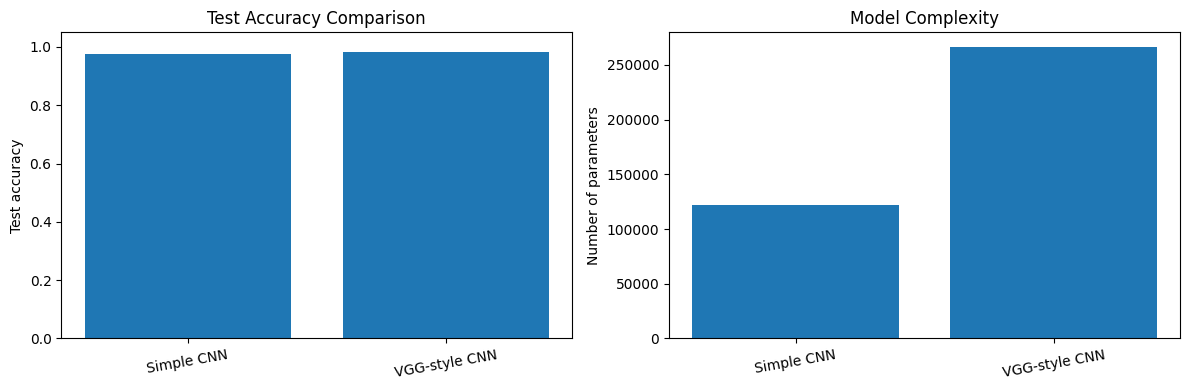

In [4]:
# Compare accuracy and model complexity
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(results_df["Model"], results_df["Test accuracy"])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Test Accuracy Comparison")

axes[1].bar(results_df["Model"], results_df["Parameters"])
axes[1].set_ylabel("Number of parameters")
axes[1].set_title("Model Complexity")

for ax in axes:
    ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

## Task 3: Compare confusion matrices and classification reports

A confusion matrix shows which digits are predicted correctly and which are confused with other digits. The classification report displays precision, recall, and F1-score for each class.

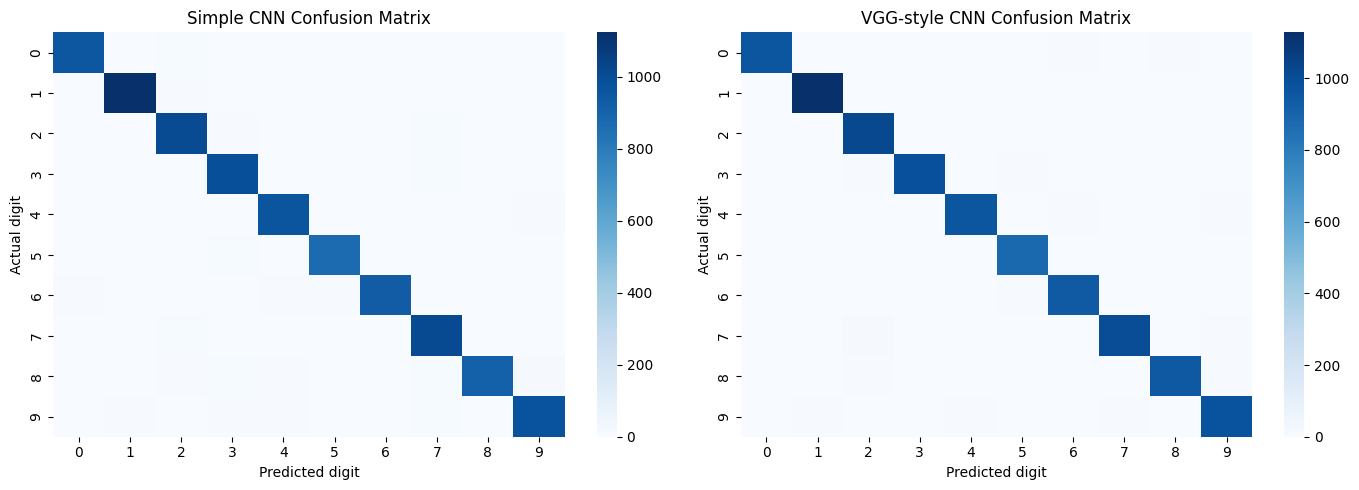

In [5]:
predictions = {}
for model_name, model in models_to_compare.items():
    probabilities = model.predict(X_test, verbose=0)
    predictions[model_name] = np.argmax(probabilities, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, model_name in zip(axes, models_to_compare.keys()):
    cm = confusion_matrix(y_test, predictions[model_name])
    sns.heatmap(cm, annot=False, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(f"{model_name} Confusion Matrix")
    ax.set_xlabel("Predicted digit")
    ax.set_ylabel("Actual digit")
plt.tight_layout()
plt.show()

In [6]:
for model_name in models_to_compare:
    print("\\n" + "=" * 55)
    print(model_name)
    print(classification_report(
        y_test,
        predictions[model_name],
        labels=list(range(10)),
        target_names=[str(i) for i in range(10)],
        digits=4,
        zero_division=0
    ))

\n=======================================================
Simple CNN
              precision    recall  f1-score   support

           0     0.9876    0.9755    0.9815       980
           1     0.9912    0.9903    0.9907      1135
           2     0.9591    0.9777    0.9683      1032
           3     0.9557    0.9822    0.9688      1010
           4     0.9797    0.9827    0.9812       982
           5     0.9798    0.9765    0.9781       892
           6     0.9863    0.9760    0.9811       958
           7     0.9529    0.9835    0.9679      1028
           8     0.9902    0.9363    0.9625       974
           9     0.9711    0.9663    0.9687      1009

    accuracy                         0.9750     10000
   macro avg     0.9754    0.9747    0.9749     10000
weighted avg     0.9753    0.9750    0.9750     10000

\n=======================================================
VGG-style CNN
              precision    recall  f1-score   support

           0     0.9959    0.9827    0.9892  

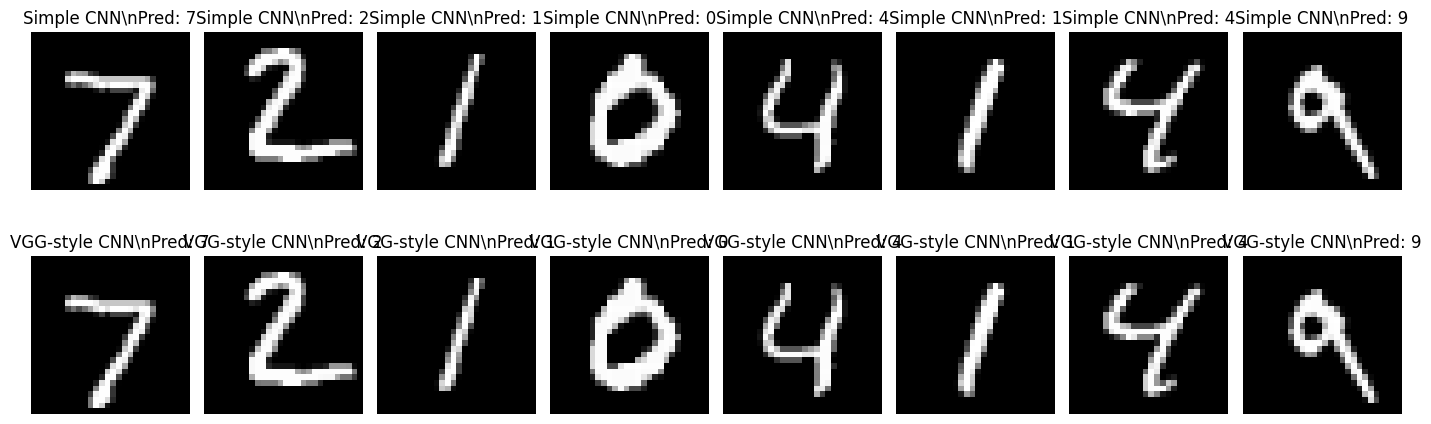

In [7]:
# Display sample predictions from the test set
fig, axes = plt.subplots(2, 8, figsize=(14, 5))
for row, model_name in enumerate(models_to_compare.keys()):
    for col in range(8):
        axes[row, col].imshow(X_test[col].squeeze(), cmap="gray")
        axes[row, col].set_title(
            f"{model_name}\\nPred: {predictions[model_name][col]}"
        )
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## Expected Output / Result

Two CNN architectures are implemented and trained using the same MNIST training subset and test set. Their test accuracy, test loss, parameter counts, and training time are displayed for comparison. The confusion matrices show the digit classes that are correctly classified and those that are frequently misclassified. The classification reports provide precision, recall, and F1-score for each digit. The results demonstrate how differences in network depth and structure can affect image classification performance and computational complexity.

## Conclusion

This project compares a basic CNN with a compact VGG-style CNN for handwritten digit classification. Evaluating both models on identical data provides a consistent comparison of their accuracy and prediction errors. The experiment shows that architecture selection should consider classification performance, model complexity, and training cost rather than depth alone.